# Pixel-wise Image Classification based on Time Series Image Representations

**Course**: AIN30306-Artificial Intelligence in Science and Engineering  
**Instructor**: Ricardo da Silva Torres  
**Institution**: Artificial Intelligence Group, Wageningen University & Research  
**Contact**: ricardo.dasilvatorres@wur.nl

Note: I used Visual Studio Code instead of Google Colab.

---
## 1. Problem Context

**Plant phenology** examines recurrent life cycle events in plants and is a key discipline for understanding the effects of climate change. To enhance the accuracy and consistency of phenological observations, recent studies have increasingly adopted new technologies. Among these, digital cameras have proven particularly effective, functioning as **multi-channel imaging sensors** that capture color variations linked to phenological events.

In this project, we monitor the **leaf-changing patterns** of Cerrado-savanna vegetation through daily digital imaging. From these images, we extract color information at the individual plant level and relate it to observed leaf phenological changes. Several vegetation indices associated with different plant species are employed for both pattern analysis and knowledge extraction.

### Main Objective

The main objective of this project is to evaluate a classifier capable of performing **pixel-wise classification** based on vegetation index time series.

---
## 2. Dataset Description

### Image Acquisition

A digital hemispherical lens camera (Mobotix Q24) was set up in an 18m tower in a Cerrado *sensu stricto*, a savanna vegetation located at Itirapina, São Paulo State, Brazil. The camera captures a daily sequence of five JPEG images (at 1280 × 960 pixels of resolution) per hour, from 6:00 to 18:00h (UTC-3). The dataset contains over **2,700 images**, recorded at the end of the dry season, between August 29th and October 3rd, 2011 (day of year 241 to 278), during the main leaf flushing season.

### Regions of Interest (ROIs)

22 ROIs from six plant species were defined:

| Species | ROIs | Color |
|---|---|---|
| *Aspidosperma tomentosum* | 3 | Red |
| *Caryocar brasiliensis* | 4 | Green |
| *Myrcia guianensis* | 2 | Blue |
| *Miconia rubiginosa* | 7 | Orange |
| *Pouteria ramiflora* | 2 | Magenta |
| *Pouteria torta* | 4 | Cyan |

### Vegetation Indices — RGB Chromatic Coordinates (RGBcc)

The normalized chromatic coordinates are the most efficient index for distinguishing plant color from background and for suppressing light variation:

$$r_{cc} = \frac{R}{R + G + B}, \quad g_{cc} = \frac{G}{R + G + B}, \quad b_{cc} = \frac{B}{R + G + B}$$

### Recurrence Plots

The recurrence plot (RP) is defined as the matrix:

$$R_{i,j} = \Theta(\varepsilon - \|\mathbf{x}_i - \mathbf{x}_j\|), \quad i,j = 1, 2, \ldots, N$$

In this project, we retain the **continuous distance values** (gray-level recurrence plots) instead of applying the Heaviside step function. The $r_{cc}$, $g_{cc}$, and $b_{cc}$ recurrence plots are combined to generate RGB images.

- Actual supplied time series: **37 time steps** → 37 × 37 pixel RP images (the template says 35)
- After upsampling (linear interpolation): **140 time steps** → 140 × 140 pixel RP images

---
## 3. Setup and Imports

For a new computer, extract the complete project ZIP and follow `START-HERE.txt`
to create the Python environment and select its notebook kernel. The notebook needs
both helper files in `casework/`, the 37 noon photographs and all 22 masks in `raw/`.
Run the cells from top to bottom. The cache is regenerated automatically and uses
about 1.53 GiB; a full run can take around 20 minutes depending on the computer.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from PIL import Image
import os
import glob

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")

All libraries imported successfully.


---
## 4. Data Loading

We load the dataset from the `raw/` directory:
- **Images**: from `raw/images/1/` — one image per hour per day (we select the noon image, hour 12, for each day).
- **Masks**: from `raw/masks/` — binary PGM masks defining each ROI.

The time series consists of 37 days (DOY 242–278). For each day, we use the **noon image** (`*_12.jpg`) as the representative observation. We also set up the spatial train/test split by selecting exactly one mask per species for training, and another one for test, keeping the pixel counts as balanced as possible.

In [2]:
# ============================================================
# Configuration
# ============================================================
import os

from pathlib import Path

# I find the project folder from the notebook's location in the extracted project.
# This works when the kernel starts in either the project folder or casework/.
# If it starts elsewhere, set PROJECT_DIR to the folder containing raw/ and casework/.
PROJECT_DIR = None
if PROJECT_DIR is None:
    working_directory = Path.cwd().resolve()
    PROJECT_DIR = next(
        (folder for folder in (working_directory, *working_directory.parents)
         if (folder / "raw").is_dir() and (folder / "casework").is_dir()),
        None,
    )
    if PROJECT_DIR is None:
        raise FileNotFoundError(
            "Project folder not found. Extract the whole project ZIP and open the "
            "notebook from its casework folder, or set PROJECT_DIR above."
        )
else:
    PROJECT_DIR = Path(PROJECT_DIR).expanduser().resolve()
RAW_DIR = os.path.join(PROJECT_DIR, "raw")
IMAGES_DIR = os.path.join(RAW_DIR, "images", "1")
MASKS_DIR = os.path.join(RAW_DIR, "masks")

for directory in (IMAGES_DIR, MASKS_DIR):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Dataset directory not found: {directory}. Check PROJECT_DIR.")

# Hour to select for the daily time series (noon)
SELECTED_HOUR = 12

# Day-of-year range
DOY_START = 242
DOY_END = 278

# Species definitions
SPECIES = {
    0: "A. tomentosum",
    1: "C. brasiliensis",
    2: "M. guianensis",
    3: "M. rubiginosa",
    4: "P. ramiflora",
    5: "P. torta",
}

SPECIES_FULL = {
    0: "Aspidosperma tomentosum",
    1: "Caryocar brasiliensis",
    2: "Myrcia guianensis",
    3: "Miconia rubiginosa",
    4: "Pouteria ramiflora",
    5: "Pouteria torta",
}

# Mask file prefix -> species class index
SPECIES_PREFIX_TO_CLASS = {
    "A.tomentosum": 0,
    "C.brasiliensis": 1,
    "M.guianensis": 2,
    "M.rubiginosa": 3,
    "P.ramiflora": 4,
    "P.torta": 5,
}

print(f"Images directory: {os.path.abspath(IMAGES_DIR)}")
print(f"Masks directory:  {os.path.abspath(MASKS_DIR)}")
print(f"Number of species: {len(SPECIES)}")

Images directory: C:\Study\2026-27\P2_AI\phenology_w2\raw\images\1
Masks directory:  C:\Study\2026-27\P2_AI\phenology_w2\raw\masks
Number of species: 6


Note: I made a sepperate directory for the course... Not sure if this is how i will do things in the near future. I am still exploring how to properly build a work flow that incoorperates github, so i can build a portfolio outside of the course, for collaborations, and also to work throughout the year with the industry standards.

### 4.1 Load Image Time Series

We select one image per day (noon) to build a time series across the 37 observation days.

In [3]:
def load_image_time_series(images_dir, doy_start, doy_end, hour=12):
    """
    Load a time series of daily images, selecting one image per day at the
    specified hour.

    Parameters
    ----------
    images_dir : str
        Path to the directory containing the JPEG images.
    doy_start : int
        First day of year (inclusive).
    doy_end : int
        Last day of year (inclusive).
    hour : int
        Hour to select for each day (default: 12 for noon).

    Returns
    -------
    images : np.ndarray
        Array of images, shape (T, H, W, 3), dtype uint8.
    doys : list of int
        Corresponding day-of-year for each loaded image.
    """
    images = []
    doys = []

    for doy in range(doy_start, doy_end + 1):
        filename = f"2011_{doy}_{hour:02d}.jpg"
        filepath = os.path.join(images_dir, filename)

        if os.path.exists(filepath):
            img = np.array(Image.open(filepath))
            images.append(img)
            doys.append(doy)
        else:
            print(f"  Warning: {filename} not found, skipping DOY {doy}")

    return np.array(images), doys


# Load the time series
images, doys = load_image_time_series(IMAGES_DIR, DOY_START, DOY_END, hour=SELECTED_HOUR)

N_TIMESTEPS = len(images)
IMG_H, IMG_W = images[0].shape[:2]

print(f"Loaded {N_TIMESTEPS} images (DOY {doys[0]}–{doys[-1]})")
print(f"Image shape: {images.shape}")
print(f"Image resolution: {IMG_W} x {IMG_H} pixels")

Loaded 37 images (DOY 242–278)
Image shape: (37, 960, 1280, 3)
Image resolution: 1280 x 960 pixels


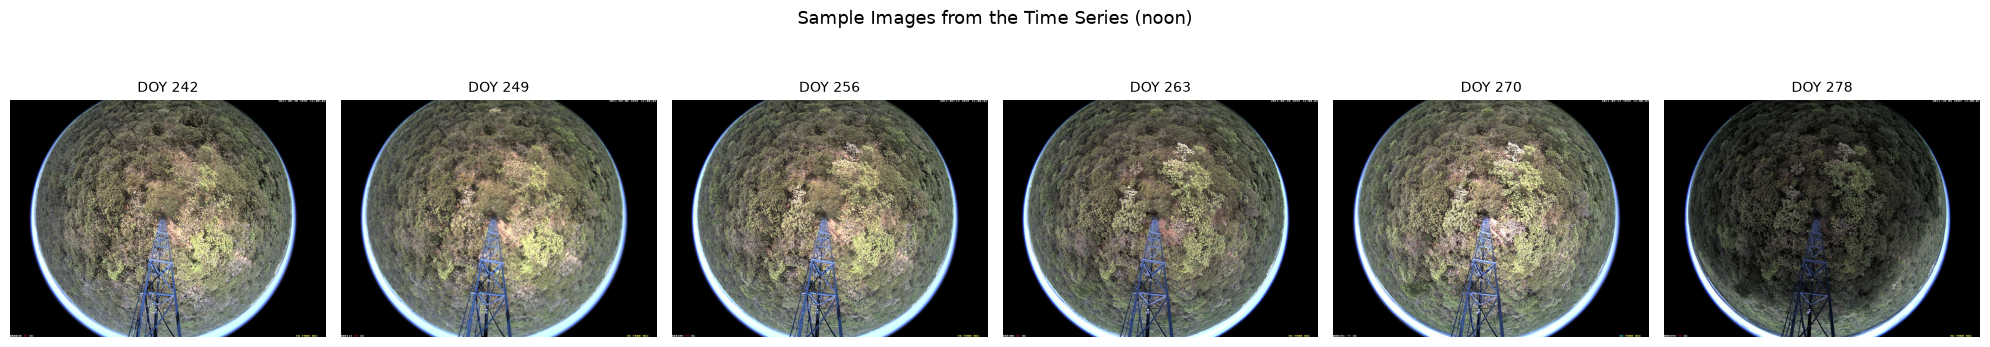

In [4]:
# Visualize a few sample images from the time series
sample_indices = np.linspace(0, N_TIMESTEPS - 1, 6, dtype=int)

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, idx in zip(axes, sample_indices):
    ax.imshow(images[idx])
    ax.set_title(f"DOY {doys[idx]}", fontsize=10)
    ax.axis("off")

fig.suptitle("Sample Images from the Time Series (noon)", fontsize=13)
plt.tight_layout()
plt.show()

### 4.2 Load Segmentation Masks

Each mask is a binary PGM image (0 = background, 255 = ROI). We parse the filenames to determine the species and ROI ID.

In [5]:
def load_masks(masks_dir, species_prefix_to_class):
    """
    Load all segmentation masks and organize them by species.

    Parameters
    ----------
    masks_dir : str
        Path to the directory containing PGM mask files.
    species_prefix_to_class : dict
        Mapping from mask filename prefix to species class index.

    Returns
    -------
    masks : list of dict
        Each dict contains:
        - 'species_class': int, species class index
        - 'species_name': str, filename prefix (e.g., 'A.tomentosum')
        - 'roi_id': int, ROI number
        - 'mask': np.ndarray, binary mask (H, W), True where ROI
        - 'n_pixels': int, number of ROI pixels
        - 'filename': str, original filename
    """
    masks = []
    mask_files = sorted(glob.glob(os.path.join(masks_dir, "*.pgm")))

    for filepath in mask_files:
        filename = os.path.basename(filepath)
        name_no_ext = filename.replace(".pgm", "")

        # Parse: "A.tomentosum_5" -> species="A.tomentosum", roi_id=5
        parts = name_no_ext.rsplit("_", 1)
        species_name = parts[0]
        roi_id = int(parts[1])

        if species_name not in species_prefix_to_class:
            print(f"  Warning: Unknown species prefix '{species_name}' in {filename}")
            continue

        species_class = species_prefix_to_class[species_name]
        mask_arr = np.array(Image.open(filepath))
        binary_mask = mask_arr > 0  # Convert to boolean

        masks.append({
            "species_class": species_class,
            "species_name": species_name,
            "roi_id": roi_id,
            "mask": binary_mask,
            "n_pixels": int(np.sum(binary_mask)),
            "filename": filename,
        })

    return masks


# Load all masks
all_masks = load_masks(MASKS_DIR, SPECIES_PREFIX_TO_CLASS)

print(f"Loaded {len(all_masks)} ROI masks:\n")
print(f"{'Species':<25s} {'ROI':>4s} {'Pixels':>8s}")
print("-" * 40)
for m in all_masks:
    print(f"{SPECIES_FULL[m['species_class']]:<25s} {m['roi_id']:>4d} {m['n_pixels']:>8d}")

Loaded 22 ROI masks:

Species                    ROI   Pixels
----------------------------------------
Aspidosperma tomentosum     11     1064
Aspidosperma tomentosum      5     1486
Aspidosperma tomentosum      7     1459
Caryocar brasiliensis        2     6601
Caryocar brasiliensis       23     7405
Caryocar brasiliensis       29     2455
Caryocar brasiliensis       31     3178
Myrcia guianensis            1     1706
Myrcia guianensis           21     1527
Miconia rubiginosa          15     1028
Miconia rubiginosa          24     5555
Miconia rubiginosa          28      836
Miconia rubiginosa          32     2111
Miconia rubiginosa          34     1582
Miconia rubiginosa           4     2064
Miconia rubiginosa           6     3069
Pouteria ramiflora          10     3001
Pouteria ramiflora           8     1283
Pouteria torta              17     2748
Pouteria torta              18     2224
Pouteria torta               3     3552
Pouteria torta               9     4028


### 4.3 Train / Test Split by ROI Assignment

To evaluate the classifier on spatially distinct regions it has never seen during training, we perform the train/test split at the **ROI level**: for each species, we select **exactly one** ROI mask for the training set and **exactly one** ROI mask for the test set.

We balance the pixel counts per species and overall as closely as possible:

| Species | Train ROI (pixels) | Test ROI (pixels) |
|---|---|---|
| *Aspidosperma tomentosum* | ROI 5 (1,486 px) | ROI 7 (1,459 px) |
| *Caryocar brasiliensis* | ROI 31 (3,178 px) | ROI 29 (2,455 px) |
| *Myrcia guianensis* | ROI 1 (1,706 px) | ROI 21 (1,527 px) |
| *Miconia rubiginosa* | ROI 4 (2,064 px) | ROI 32 (2,111 px) |
| *Pouteria ramiflora* | ROI 8 (1,283 px) | ROI 10 (3,001 px) |
| *Pouteria torta* | ROI 9 (4,028 px) | ROI 3 (3,552 px) |

- **Total Training Pixels**: 13,745 (49.4%)
- **Total Testing Pixels**: 14,105 (50.6%)

In [6]:
# ============================================================
# Train / Test split by ROI assignment
# ============================================================

# Define exactly one train mask and exactly one test mask per species
TRAIN_ROIS = {
    "A.tomentosum": [5],
    "C.brasiliensis": [31],
    "M.guianensis": [1],
    "M.rubiginosa": [4],
    "P.ramiflora": [8],
    "P.torta": [9],
}

TEST_ROIS = {
    "A.tomentosum": [7],
    "C.brasiliensis": [29],
    "M.guianensis": [21],
    "M.rubiginosa": [32],
    "P.ramiflora": [10],
    "P.torta": [3],
}


def split_masks_by_roi(all_masks, train_rois, test_rois):
    """
    Split the loaded masks into train and test sets based on ROI assignments.

    Parameters
    ----------
    all_masks : list of dict
        All loaded mask entries.
    train_rois : dict
        Species -> list of ROI IDs for training.
    test_rois : dict
        Species -> list of ROI IDs for testing.

    Returns
    -------
    train_masks : list of dict
        Masks assigned to the training set.
    test_masks : list of dict
        Masks assigned to the test set.
    """
    train_masks = []
    test_masks = []

    for m in all_masks:
        species = m["species_name"]
        roi_id = m["roi_id"]

        if species in train_rois and roi_id in train_rois[species]:
            train_masks.append(m)
        elif species in test_rois and roi_id in test_rois[species]:
            test_masks.append(m)

    return train_masks, test_masks


train_masks, test_masks = split_masks_by_roi(all_masks, TRAIN_ROIS, TEST_ROIS)

print(f"Training ROIs: {len(train_masks)}")
print(f"Test ROIs:     {len(test_masks)}")

Training ROIs: 6
Test ROIs:     6


In [7]:
# Summary of train/test split pixel counts
print(f"\n{'Split':>7s} | {'Species':<25s} | {'ROI':>4s} | {'Pixels':>7s}")
print("-" * 55)

for m in train_masks:
    print(f"{'TRAIN':>7s} | {SPECIES_FULL[m['species_class']]:<25s} | {m['roi_id']:>4d} | {m['n_pixels']:>7d}")

print("-" * 55)

for m in test_masks:
    print(f"{'TEST':>7s} | {SPECIES_FULL[m['species_class']]:<25s} | {m['roi_id']:>4d} | {m['n_pixels']:>7d}")

# Pixel count summary per species
print("\n" + "=" * 60)
print(f"{'Species':<25s} | {'Train px':>10s} | {'Test px':>10s} | {'Ratio':>6s}")
print("-" * 60)

for cls_id in range(6):
    train_px = sum(m["n_pixels"] for m in train_masks if m["species_class"] == cls_id)
    test_px = sum(m["n_pixels"] for m in test_masks if m["species_class"] == cls_id)
    total = train_px + test_px
    ratio = f"{train_px / total:.0%}" if total > 0 else "N/A"
    print(f"{SPECIES_FULL[cls_id]:<25s} | {train_px:>10d} | {test_px:>10d} | {ratio:>6s}")

total_train_px = sum(m["n_pixels"] for m in train_masks)
total_test_px = sum(m["n_pixels"] for m in test_masks)
grand_total = total_train_px + total_test_px
print("-" * 60)
print(f"{'Total (All Species)':<25s} | {total_train_px:>10d} | {total_test_px:>10d} | {total_train_px/grand_total:>6.1%}")


  Split | Species                   |  ROI |  Pixels
-------------------------------------------------------
  TRAIN | Aspidosperma tomentosum   |    5 |    1486
  TRAIN | Caryocar brasiliensis     |   31 |    3178
  TRAIN | Myrcia guianensis         |    1 |    1706
  TRAIN | Miconia rubiginosa        |    4 |    2064
  TRAIN | Pouteria ramiflora        |    8 |    1283
  TRAIN | Pouteria torta            |    9 |    4028
-------------------------------------------------------
   TEST | Aspidosperma tomentosum   |    7 |    1459
   TEST | Caryocar brasiliensis     |   29 |    2455
   TEST | Myrcia guianensis         |   21 |    1527
   TEST | Miconia rubiginosa        |   32 |    2111
   TEST | Pouteria ramiflora        |   10 |    3001
   TEST | Pouteria torta            |    3 |    3552

Species                   |   Train px |    Test px |  Ratio
------------------------------------------------------------
Aspidosperma tomentosum   |       1486 |       1459 |    50%
Caryocar brasi

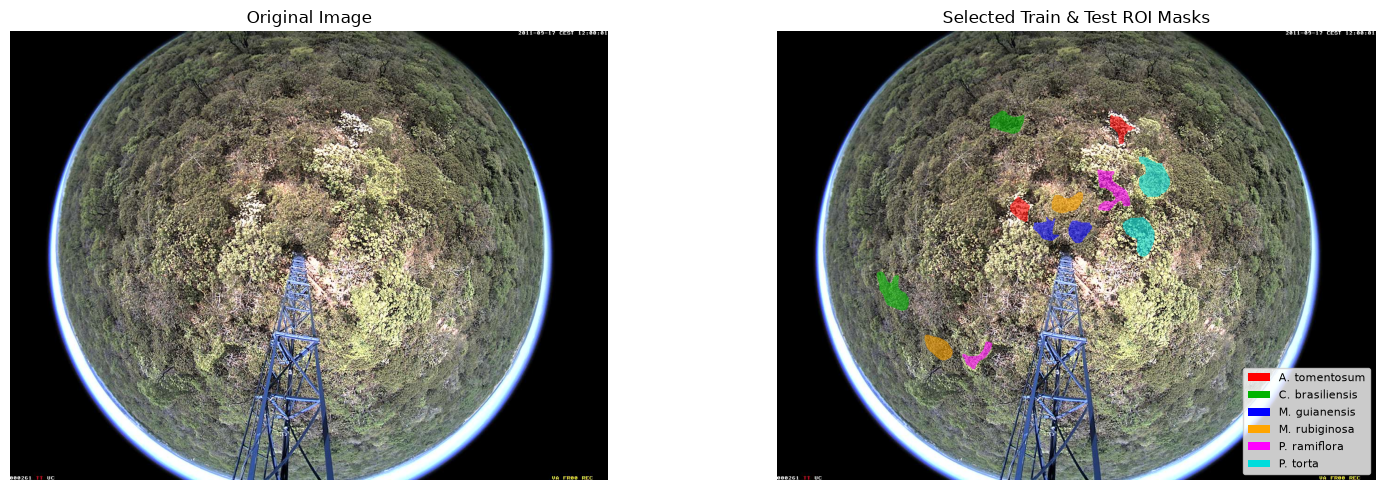

In [8]:
# Visualize the masks overlaid on a sample image
COLORS = {
    0: [255, 0, 0],       # Red - A. tomentosum
    1: [0, 180, 0],       # Green - C. brasiliensis
    2: [0, 0, 255],       # Blue - M. guianensis
    3: [255, 165, 0],     # Orange - M. rubiginosa
    4: [255, 0, 255],     # Magenta - P. ramiflora
    5: [0, 220, 220],     # Cyan - P. torta
}

overlay = images[N_TIMESTEPS // 2].copy()
for m in train_masks + test_masks:
    color = COLORS[m["species_class"]]
    overlay[m["mask"]] = (
        0.4 * overlay[m["mask"]] + 0.6 * np.array(color)
    ).astype(np.uint8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.imshow(images[N_TIMESTEPS // 2])
ax1.set_title("Original Image")
ax1.axis("off")

ax2.imshow(overlay)
ax2.set_title("Selected Train & Test ROI Masks")
ax2.axis("off")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=np.array(COLORS[i]) / 255, label=SPECIES[i])
    for i in range(6)
]
ax2.legend(handles=legend_elements, loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

---
## 5. Compute RGB Chromatic Coordinates

Compute the normalized chromatic coordinates ($r_{cc}$, $g_{cc}$, $b_{cc}$) for each pixel in the time series.

In [9]:
def compute_chromatic_coordinates(image):
    """
    Compute the RGB chromatic coordinates for a given image.

    Parameters
    ----------
    image : np.ndarray
        Input image of shape (H, W, 3) with R, G, B channels.

    Returns
    -------
    r_cc : np.ndarray
        Red chromatic coordinate, shape (H, W).
    g_cc : np.ndarray
        Green chromatic coordinate, shape (H, W).
    b_cc : np.ndarray
        Blue chromatic coordinate, shape (H, W).
    """

    # TODO: Implement chromatic coordinate computation
    # r_cc = R / (R + G + B)
    # g_cc = G / (R + G + B)
    # b_cc = B / (R + G + B)
    # Handle division by zero (e.g., black pixels)

    # Note to self: This part (below) is where i have to do stuff
    # Okay so convert to float before adding channels to avoid integer overflow
    image_float = image.astype(np.float32)

    R = image_float[:, :, 0]
    G = image_float[:, :, 1]
    B = image_float[:, :, 2]

    total = R + G + B
    # avoid division by zero by setting total to 1 where it is zero
    total[total == 0] = 1

    r_cc = R / total
    g_cc = G / total
    b_cc = B / total

    return r_cc, g_cc, b_cc

In [10]:
# here is also were I had to do stuff
# Calculate each colour channel's proportion of total RGB intensity
chromatic_series = []

for image in images:
    r_cc, g_cc, b_cc = compute_chromatic_coordinates(image)
    chromatic_series.append((r_cc, g_cc, b_cc))

print(f"Processed {len(chromatic_series)} images.")


Processed 37 images.


Quick note: Im marking the parts were i have to implement code so i can review it also later (and also to describe what i did, so i understand the steps).

---
## 6. Extract Time Series per ROI

For each ROI, compute the mean chromatic coordinate values across the region at each time step, resulting in a 1D time series per channel per ROI.

In [11]:
def extract_roi_time_series(chromatic_series, mask):
    """Return three arrays of daily mean colour proportions for one ROI."""

    # I need at least one selected pixel to calculate a 'meaningful' average
    if not mask.any():
        raise ValueError("The ROI mask does not select any pixels.")

    # I keep a separate list of daily averages for red, green and blue
    r_cc_ts = []
    g_cc_ts = []
    b_cc_ts = []

    # I reuse my Section 5 results and visit the images in time order
    for r_cc, g_cc, b_cc in chromatic_series:
        # I select only this ROI's pixels, then average their colour proportions.
        r_cc_ts.append(r_cc[mask].mean())
        g_cc_ts.append(g_cc[mask].mean())
        b_cc_ts.append(b_cc[mask].mean())

    # I return one array per channel, with one value for each day
    return np.array(r_cc_ts), np.array(g_cc_ts), np.array(b_cc_ts)


# I store each ROI's three time series alongside its species class
# I keep both lists in the same order as all_masks so I can identify each ROI
time_series_data = []
labels = []

for roi in all_masks:
    roi_series = extract_roi_time_series(chromatic_series, roi["mask"])
    time_series_data.append(roi_series)
    labels.append(roi["species_class"])

# I use these averages to summarize ROIs; I keep chromatic_series for
# the later classification task, where each individual pixel is a sample
print(f"Extracted time series for {len(time_series_data)} ROIs.")
print(f"Each ROI has 3 colour series with {len(chromatic_series)} daily values.")


Extracted time series for 22 ROIs.
Each ROI has 3 colour series with 37 daily values.


Note to self: In this section color proportions from section 5, where turned into a daily summary for each region of interest (ROI). Subsequently, each ROI mask is then used to select only the pixels belonging to that region. For each day the average red, green and blue chromatic coordinates are calculated across these selected pixels. When repeated in time order, the outputs should be three time series for each ROI: (red, green and blue). Each time series contains 37 values, corresponding to the 37 observation days.

The resulting time series for all 22 ROI's are stored in 'time_series_data', while their corresponding species classes are stored in 'labels'. Both follow the same order to ensure ROI's results correspont to the same species.

In short: these averages describe how the color proportions within each region change over time. The individual pixel-level chromatic coordinates are retained in 'chromatic_series'. 

---
## Exercise 1: Construct Recurrence Plot Images

Build recurrence plot images from the vegetation index time series as described in the dataset preparation procedure.

**Steps:**
1. Upsample each actual 37-observation time series to 140 positions using linear interpolation. Preserve the first and last observation; the template's 35 differs from the supplied data.
2. Compute the gray-level recurrence plot (continuous distance matrix) for each channel.
3. Combine the $r_{cc}$, $g_{cc}$, and $b_{cc}$ recurrence plots into RGB images.

In [12]:
def upsample_time_series(ts, target_length=140):
    """Resample a time series using linear interpolation."""

    # I locate each existing value at its position in the series
    original_positions = np.arange(len(ts))

    # I create evenly spaced positions across the same time span
    new_positions = np.linspace(0, len(ts) - 1, target_length)

    # I connect neighboring observations with straight lines
    interpolator = interp1d(original_positions, ts, kind="linear")

    # I calculate and return the values at the new positions
    return interpolator(new_positions)

In [13]:
# This is a simple test to check that the upsampling function works as expected
example = np.array([0.2, 0.6])
print(upsample_time_series(example, target_length=5))

# I check the output length using my first ROI's red time series
print(upsample_time_series(time_series_data[0][0]).shape)

[0.2 0.3 0.4 0.5 0.6]
(140,)


In [14]:
def compute_recurrence_plot(ts):
    """Calculate the distance between every pair of time-series values"""

    # I arrange my values in a column, with one time point per row
    values = np.asarray(ts).reshape(-1, 1)

    # I compare every value with every other value
    # For one color channel, Euclidean distance is the absolute difference
    rp = cdist(values, values, metric="euclidean")

    # I return the distance matrix for this color channel
    return rp

In [15]:
# This is a simple test to check that the recurrence plot function works as expected
example = np.array([0.2, 0.5, 0.3])
print(np.round(compute_recurrence_plot(example), 2))

# I check the matrix size using my interpolated red time series
red_upsampled = upsample_time_series(time_series_data[0][0])
print(compute_recurrence_plot(red_upsampled).shape)

[[0.  0.3 0.1]
 [0.3 0.  0.2]
 [0.1 0.2 0. ]]
(140, 140)


In [16]:
def create_rgb_recurrence_plot(r_cc_ts, g_cc_ts, b_cc_ts):
    """Create an RGB recurrence plot with shape (140, 140, 3)."""

    # I collect the three image channels in red, green, blue order
    channels = []

    for ts in (r_cc_ts, g_cc_ts, b_cc_ts):
        # I interpolate this color's time series to 140 values
        ts_upsampled = upsample_time_series(ts)

        # I calculate the distance between every pair of values
        rp = compute_recurrence_plot(ts_upsampled)

        # I find the largest distance to scale this channel's brightness
        # The smallest distance is already zero along the diagonal
        max_distance = rp.max()

        if max_distance > 0:
            # I scale the distances to 0–255 and store them as image values
            scaled_rp = np.round(255 * rp / max_distance).astype(np.uint8)
        else:
            # If this color never changes, all distances are zero
            # I keep this channel at zero and avoid division by zero
            scaled_rp = np.zeros_like(rp, dtype=np.uint8)

        channels.append(scaled_rp)

    # I combine the three matrices along a new color dimension
    return np.stack(channels, axis=-1)

(140, 140, 3)
uint8


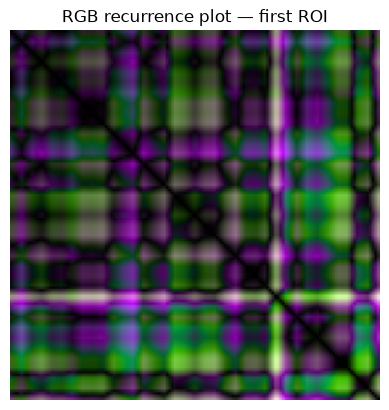

In [17]:
# I use my first ROI's average time series to preview the result
r_ts, g_ts, b_ts = time_series_data[0]
example_rp = create_rgb_recurrence_plot(r_ts, g_ts, b_ts)

print(example_rp.shape)
print(example_rp.dtype)

plt.imshow(example_rp)
plt.title("RGB recurrence plot — first ROI")
plt.axis("off")
plt.show()

In [18]:
# I check that every ROI time series has a corresponding species label
assert len(time_series_data) == len(labels)

# I collect the recurrence images and their matching species labels
rp_images = []
rp_labels = []

# I use zip to visit each ROI's time series and its label together
for roi_series, species_class in zip(time_series_data, labels):
    r_ts, g_ts, b_ts = roi_series

    # I combine this ROI's three color series into one recurrence image
    rgb_rp = create_rgb_recurrence_plot(r_ts, g_ts, b_ts)

    # I preserve the same order in both lists so images and labels stay matched
    rp_images.append(rgb_rp)
    rp_labels.append(species_class)

# I organize the images and labels into arrays for easier use later
rp_images = np.stack(rp_images)
rp_labels = np.array(rp_labels)

print(f"Recurrence images: {rp_images.shape}")
print(f"Species labels: {rp_labels.shape}")


Recurrence images: (22, 140, 140, 3)
Species labels: (22,)


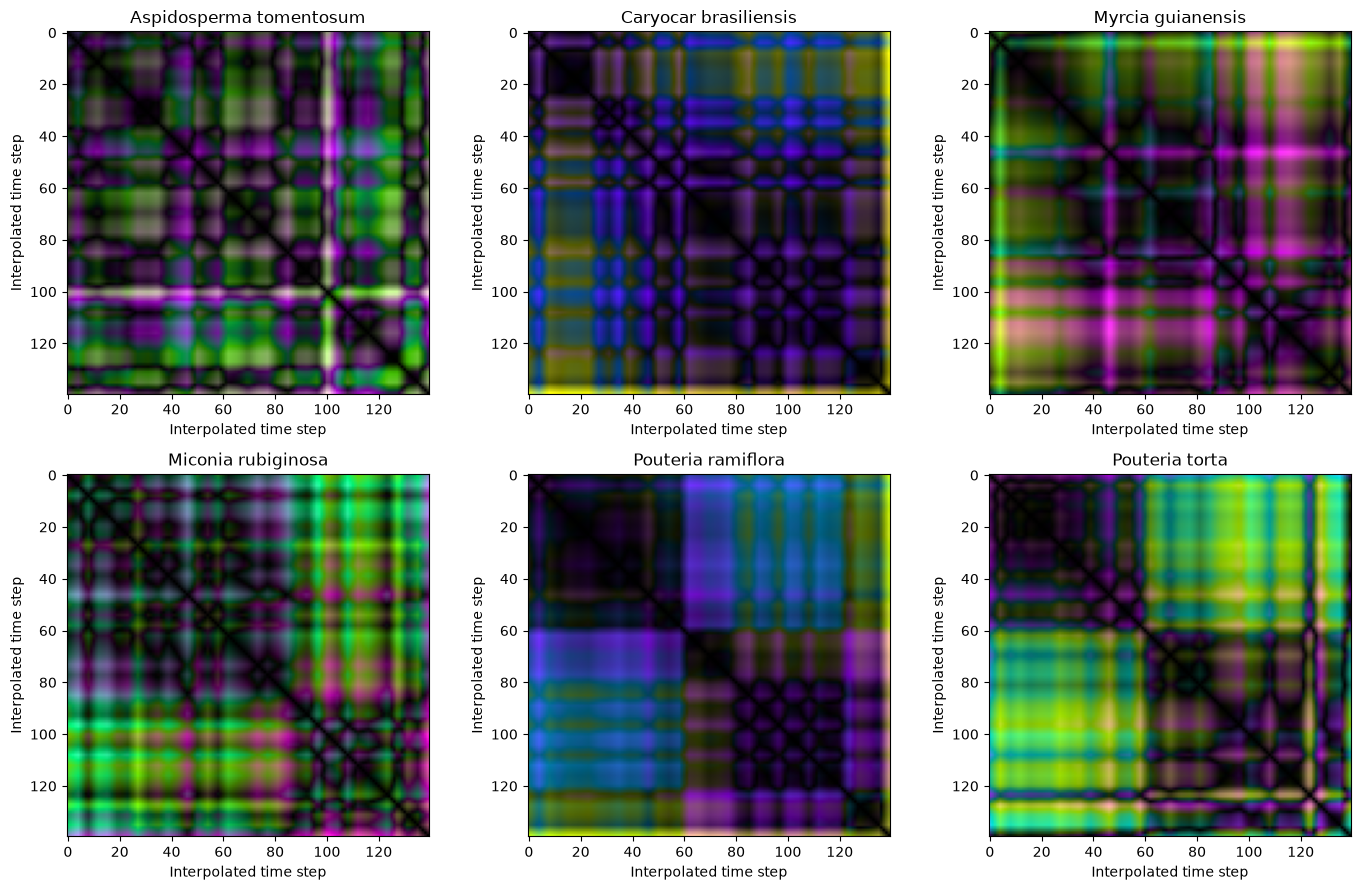

In [19]:
# I find the first recurrence image belonging to each species.
species_classes, example_indices = np.unique(
    rp_labels, return_index=True
)

# I create six subplots so I can compare the species side by side.
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, species_class, image_index in zip(
    axes.flat, species_classes, example_indices
):
    # I display this ROI's image and identify its species.
    ax.imshow(rp_images[image_index])
    ax.set_title(SPECIES_FULL[int(species_class)])

    # Both axes represent positions in the interpolated time series.
    ax.set_xlabel("Interpolated time step")
    ax.set_ylabel("Interpolated time step")

# I adjust the spacing so the titles and labels remain readable.
plt.tight_layout()
plt.show()


The 22 images above summarize entire ROIs. The classifiers below instead use one
sample per original camera pixel, retaining all 37 daily observations. Both uses
share the same interpolation and recurrence functions.

Each channel contains continuous pairwise Euclidean distances before image
conversion; there is no threshold or epsilon. Its maximum distance is scaled
independently to 255 and values are rounded to `uint8`; a constant channel stays
zero. This consistent rule removes absolute distance scale and introduces
quantization. Linear interpolation evaluates the original piecewise-linear curve
at 140 positions; it adds no independent observations.

---
## Exercise 2: Split the Data

**Execution-order correction (11 November 2026):** The template asks for a split
before the feature preparation described in Exercises 3 and 4. The ordering issue
has been reported to Ricardo. Here we move raw pixel preparation before the split,
then save shared row indices. Exercise 3 uses those features; Exercise 4 constructs
recurrence images in the same row order and applies the same indices. Classifier
fitting follows splitting, so the notebook can run from top to bottom.

Section 4.3 fixes the separate training and test ROIs. We keep all their pixels,
split only the training-ROI pixels 80/20 with stratification and seed 42, and leave
every test-ROI pixel held out. Disjoint pixel coordinates prevent direct pixel
overlap; they do not make neighbouring pixels statistically independent.

**One row = one pixel across 37 days.** Raw columns are the 37 red chromatic
coordinates, then 37 green, then 37 blue. We retain species, ROI, row and column
identity so both representations and their predictions remain traceable.

In [20]:
# First I prepare the pixel features, because the next step needs something to split.
# This brings the data preparation from Exercise 3 forward so the cells run in order.
from pathlib import Path
import sys
import json
import inspect
from time import perf_counter
import scipy

# I load the local helpers for extracting pixels, saving data and finding neighbours.
project_path = Path(PROJECT_DIR)
if str(project_path / "casework") not in sys.path:
    sys.path.insert(0, str(project_path / "casework"))
from phenology_data import extract_pixel_features, save_pixel_dataset, build_recurrence_cache
from knn_utils import exact_neighbors, uniform_predictions

RESULTS_DIR = project_path / "results"
CACHE_DIR = project_path / "cache"
RESULTS_DIR.mkdir(exist_ok=True)

# Each row is one pixel: all 37 red values, then green, then blue.
# I keep its species label and location too, so I can follow it through both models.
raw_started = perf_counter()
X_ts_trainval, y_ts_trainval, ids_trainval = extract_pixel_features(chromatic_series, train_masks)
X_ts_test, y_ts_test, ids_test = extract_pixel_features(chromatic_series, test_masks)
raw_generation_seconds = perf_counter() - raw_started

# I check the pixel counts and dates before using the extracted features.
assert X_ts_trainval.shape == (13745, 3 * N_TIMESTEPS)
assert X_ts_test.shape == (14105, 3 * N_TIMESTEPS)
assert N_TIMESTEPS == 37 and np.array_equal(doys, np.arange(242, 279))
# As a quick check, I compare the first extracted row with its original RGBcc values.
_, _, row, column = ids_trainval[0]
expected = np.array([[channels[c][row, column] for channels in chromatic_series]
                     for c in range(3)], dtype=np.float32).ravel()
np.testing.assert_array_equal(X_ts_trainval[0], expected)
print(f"Training-ROI features: {X_ts_trainval.shape}; test-ROI features: {X_ts_test.shape}")
print(f"Feature order: r[37], g[37], b[37]; extraction: {raw_generation_seconds:.3f} s")
print(f"Python environment: {sys.executable}")

Training-ROI features: (13745, 111); test-ROI features: (14105, 111)
Feature order: r[37], g[37], b[37]; extraction: 0.146 s
Python environment: C:\Study\2026-27\P2_AI\phenology_w2\.venv\Scripts\python.exe


In [21]:
# I split only the training-region pixels; the separate test regions stay held out.
# Saving row numbers lets both models use exactly the same training and validation pixels.
# Stratification keeps the species proportions similar in these two groups.
train_indices, val_indices = train_test_split(
    np.arange(len(y_ts_trainval)), test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_ts_trainval,
)
# These checks make sure each training-region pixel belongs to exactly one group.
assert len(train_indices) == 10996 and len(val_indices) == 2749
assert not np.intersect1d(train_indices, val_indices).size
np.testing.assert_array_equal(
    np.sort(np.concatenate([train_indices, val_indices])), np.arange(13745)
)
# I print the counts per species to see how the samples are distributed.
print(f"Training: {len(train_indices):,}; validation: {len(val_indices):,}; test: {len(y_ts_test):,}")
print(f"{'Species':<20} {'Train':>7} {'Val':>7} {'Test':>7}")
for cls, name in SPECIES.items():
    counts = [(labels == cls).sum() for labels in
              (y_ts_trainval[train_indices], y_ts_trainval[val_indices], y_ts_test)]
    print(f"{name:<20} {counts[0]:7d} {counts[1]:7d} {counts[2]:7d}")

Training: 10,996; validation: 2,749; test: 14,105
Species                Train     Val    Test
A. tomentosum           1189     297    1459
C. brasiliensis         2542     636    2455
M. guianensis           1365     341    1527
M. rubiginosa           1651     413    2111
P. ramiflora            1027     256    3001
P. torta                3222     806    3552


In [22]:
# I save the features, labels, pixel locations and split together in one file.
# This keeps the row numbers linked to the pixels they actually describe.
dataset_path = save_pixel_dataset(
    RESULTS_DIR / "pixel_dataset.npz",
    X_trainval=X_ts_trainval, y_trainval=y_ts_trainval, ids_trainval=ids_trainval,
    X_test=X_ts_test, y_test=y_ts_test, ids_test=ids_test,
    train_indices=train_indices, val_indices=val_indices,
    doys=doys, random_state=RANDOM_STATE,
)
# The saving helper checks that labels match and no pixel coordinates are repeated.
# I reopen the file to check that the saved training indices and test identities match.
with np.load(dataset_path, allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["train_indices"], train_indices)
    np.testing.assert_array_equal(saved["ids_test"], ids_test)
print(f"Saved histories, labels, pixel identities and shared split: {dataset_path.name}")

Saved histories, labels, pixel identities and shared split: pixel_dataset.npz


---
## Exercise 3: K-NN on Raw Time Series

Here "raw" means the 111 RGB chromatic-coordinate features before recurrence
transformation, not unnormalized JPEG intensities. Preparation is above Exercise
2's split to resolve the template dependency.

Both experiments use exact Euclidean K-NN with uniform voting. A small helper
computes distances in memory-bounded blocks, keeping the nearest 15 neighbours;
prefixes of that same ranking evaluate K = 1, 3, 5, 7, 9, 11, 15 without repeating
the distance computation. Equal distances are ordered by source pixel row index;
tied class votes choose the smallest class ID. Equal validation scores choose
the smallest K. The helper is checked against scikit-learn separately.

Select K using validation accuracy only. As in the template, the final model
retains the 10,996 training pixels; it is not refitted on training plus validation.
Test labels are used only to evaluate the selected configuration.

In [23]:
# Here I use the saved row numbers to separate the raw features and their labels.
# The neighbour helper below reads the original arrays using these same row numbers.
X_ts_train, X_ts_val = X_ts_trainval[train_indices], X_ts_trainval[val_indices]
y_ts_train, y_ts_val = y_ts_trainval[train_indices], y_ts_trainval[val_indices]
# K is how many neighbours vote for a species. I compare these choices on validation.
k_values = [1, 3, 5, 7, 9, 11, 15]
print(f"Raw features — train {X_ts_train.shape}, validation {X_ts_val.shape}, test {X_ts_test.shape}")

Raw features — train (10996, 111), validation (2749, 111), test (14105, 111)


In [24]:
raw_knn_started = perf_counter()
# I find the nearest 15 training pixels once, then reuse that ranking for each K.
# train_indices makes sure validation pixels cannot become their own neighbours.
ts_val_distances, ts_val_neighbors = exact_neighbors(
    X_ts_trainval, X_ts_trainval, max(k_values),
    train_indices=train_indices, query_indices=val_indices, progress=True,
)
# Each neighbour gets one vote. I score the predictions against the validation labels.
val_accuracies = []
for k in k_values:
    prediction = uniform_predictions(ts_val_neighbors, y_ts_trainval, k)
    val_accuracies.append(accuracy_score(y_ts_val, prediction))
    print(f"K={k:2d}: validation accuracy = {val_accuracies[-1]:.4f}")
# I choose K using validation accuracy only; the test scores do not influence it.
best_k_ts = k_values[int(np.argmax(val_accuracies))]
raw_validation_seconds = perf_counter() - raw_knn_started

# Now I use the chosen K on the separate test regions.
# The neighbours still come from the training pixels; I do not add validation pixels.
test_started = perf_counter()
ts_test_distances, ts_test_neighbors = exact_neighbors(
    X_ts_trainval, X_ts_test, best_k_ts, train_indices=train_indices, progress=True,
)
y_ts_test_pred = uniform_predictions(ts_test_neighbors, y_ts_trainval, best_k_ts)
raw_test_seconds = perf_counter() - test_started
# The validation scores above are for choosing K. This next score is the test result.
print(f"Selected K: {best_k_ts}; full held-out test accuracy: {accuracy_score(y_ts_test, y_ts_test_pred):.4f}")
print(classification_report(y_ts_test, y_ts_test_pred, labels=list(SPECIES),
                            target_names=list(SPECIES_FULL.values()), zero_division=0))

Neighbours: 2,749/2,749 query pixels; 4.5 s


K= 1: validation accuracy = 0.9222
K= 3: validation accuracy = 0.9287
K= 5: validation accuracy = 0.9247
K= 7: validation accuracy = 0.9229
K= 9: validation accuracy = 0.9192
K=11: validation accuracy = 0.9214
K=15: validation accuracy = 0.9160


Neighbours: 6,464/14,105 query pixels; 10.1 s


Neighbours: 13,888/14,105 query pixels; 20.1 s


Neighbours: 14,105/14,105 query pixels; 20.4 s


Selected K: 3; full held-out test accuracy: 0.2654
                         precision    recall  f1-score   support

Aspidosperma tomentosum       0.37      0.67      0.48      1459
  Caryocar brasiliensis       0.17      0.11      0.13      2455
      Myrcia guianensis       0.22      0.59      0.32      1527
     Miconia rubiginosa       0.01      0.01      0.01      2111
     Pouteria ramiflora       0.10      0.02      0.04      3001
         Pouteria torta       0.38      0.42      0.40      3552

               accuracy                           0.27     14105
              macro avg       0.21      0.30      0.23     14105
           weighted avg       0.21      0.27      0.22     14105



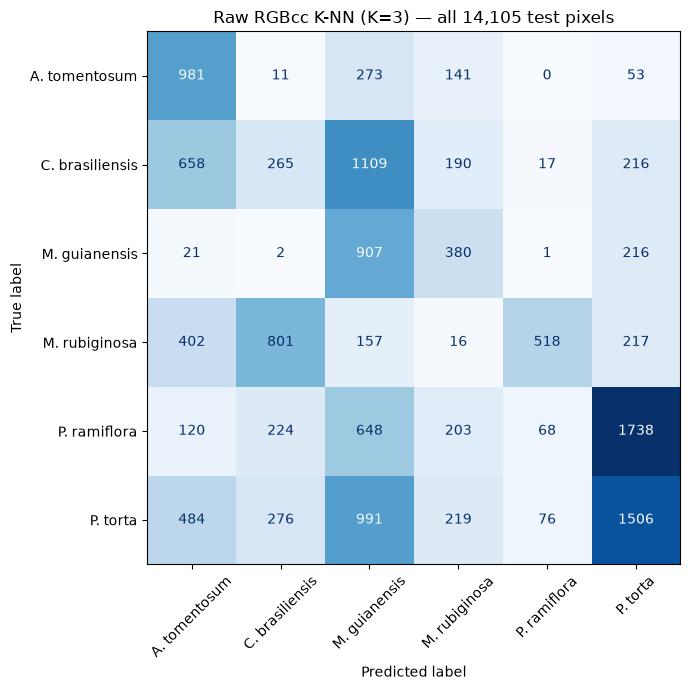

In [25]:
# Rows show the actual species and columns show the predicted species.
# The diagonal contains correct predictions; the other cells show the mix-ups.
cm_ts = confusion_matrix(y_ts_test, y_ts_test_pred, labels=list(SPECIES))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm_ts, display_labels=list(SPECIES.values())).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Raw RGBcc K-NN (K={best_k_ts}) — all {len(y_ts_test):,} test pixels")
plt.tight_layout()
plt.show()

---
## Exercise 4: K-NN on Recurrence Plot Images

Construct one 140 × 140 × 3 RGB image for every selected pixel, in exactly the
same row order as the raw dataset. Store the full flattened images as `uint8`
arrays on disk. The cache records the feature content, transformation sources,
settings and checksums; changed inputs or code require a new cache.

Use the shared Exercise 2 indices without copying the whole recurrence dataset
into memory. The helper may exploit verified symmetry and zero diagonals:
full squared Euclidean distance equals twice the squared distance between the
strict upper triangles. This removes duplicate arithmetic while retaining the
exact full-image distance and neighbour ranking. It is not an approximation,
learned dimensionality reduction or a reduction in the number of samples.

rp_trainval: generated 2,000/13,745 pixel recurrence images


rp_trainval: generated 4,000/13,745 pixel recurrence images


rp_trainval: generated 6,000/13,745 pixel recurrence images


rp_trainval: generated 8,000/13,745 pixel recurrence images


rp_trainval: generated 10,000/13,745 pixel recurrence images


rp_trainval: generated 12,000/13,745 pixel recurrence images


... (6 outputs left out)

rp_test: generated 12,000/14,105 pixel recurrence images


rp_test: generated 14,000/14,105 pixel recurrence images


rp_test: generated 14,105/14,105 pixel recurrence images


Full recurrence arrays: (13745, 58800), (14105, 58800)
Disk-array storage: 1.525 GiB
Cache preparation/load this run: 45.68 s; reused: False, False


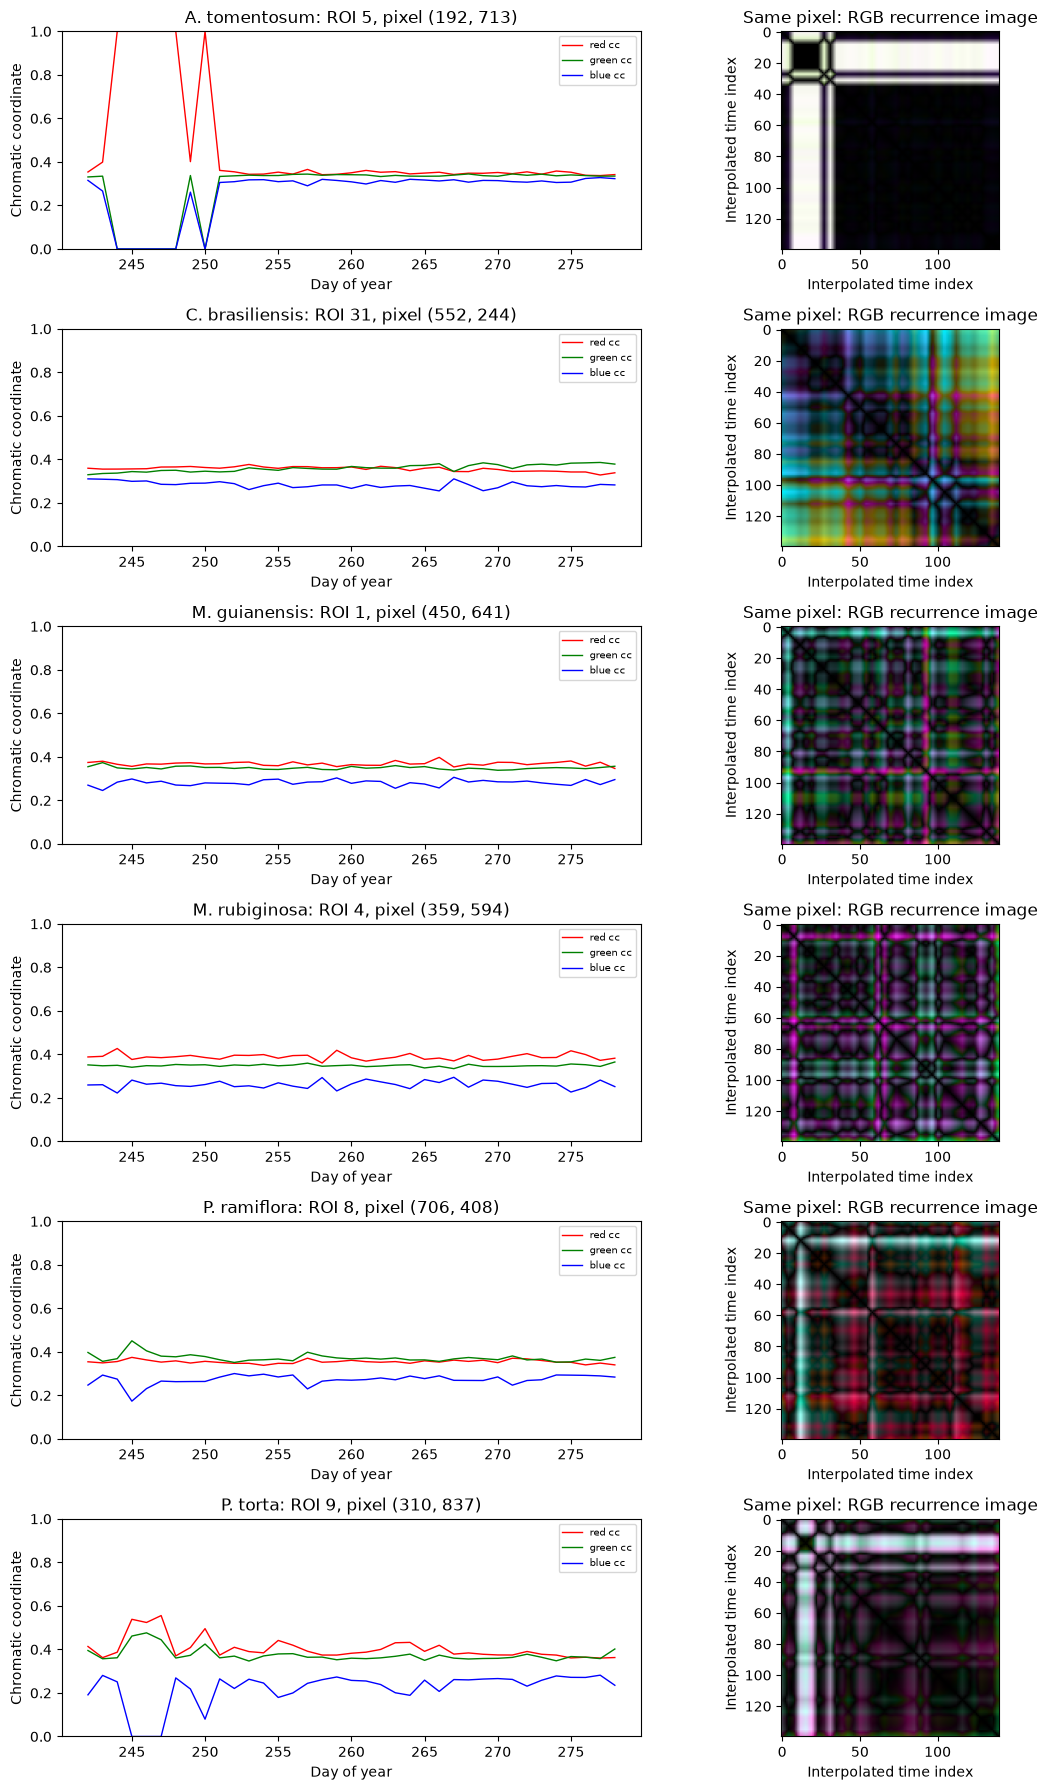

In [26]:
# I record the transformation and settings so cached images can be checked before reuse.
# Matching inputs, code and settings let me reuse the images on a later run.
transform_signature = json.dumps({
    "sources": [inspect.getsource(f) for f in
                (upsample_time_series, compute_recurrence_plot, create_rgb_recurrence_plot)],
    "numpy": np.__version__, "scipy": scipy.__version__,
    "observations": N_TIMESTEPS, "target_length": 140,
    "normalization": "separate image/channel maximum; round to uint8 0..255",
}, sort_keys=True)
# These full image arrays stay on disk and are read in parts to limit memory use.
cache_started = perf_counter()
X_rp_trainval, rp_trainval_info = build_recurrence_cache(
    X_ts_trainval, CACHE_DIR, "rp_trainval", create_rgb_recurrence_plot,
    transform_signature=transform_signature, progress=True,
)
X_rp_test, rp_test_info = build_recurrence_cache(
    X_ts_test, CACHE_DIR, "rp_test", create_rgb_recurrence_plot,
    transform_signature=transform_signature, progress=True,
)
rp_cache_seconds = perf_counter() - cache_started
# The images keep the same row order as the raw features, so I can reuse their labels.
y_rp_trainval, y_rp_test = y_ts_trainval, y_ts_test
y_rp_train, y_rp_val = y_rp_trainval[train_indices], y_rp_trainval[val_indices]
# Each flattened RGB image has 140 x 140 x 3 = 58,800 values.
assert X_rp_trainval.shape == (13745, 58800) and X_rp_test.shape == (14105, 58800)
# I compare three cached rows with freshly generated images as a quick check.
for index in [0, len(X_ts_trainval) // 2, len(X_ts_trainval) - 1]:
    expected = create_rgb_recurrence_plot(*X_ts_trainval[index].reshape(3, N_TIMESTEPS))
    np.testing.assert_array_equal(X_rp_trainval[index], expected.ravel())
print(f"Full recurrence arrays: {X_rp_trainval.shape}, {X_rp_test.shape}")
print(f"Disk-array storage: {(X_rp_trainval.nbytes + X_rp_test.nbytes) / 2**30:.3f} GiB")
print(f"Cache preparation/load this run: {rp_cache_seconds:.2f} s; reused: {rp_trainval_info['reused']}, {rp_test_info['reused']}")

# I put one training pixel's colour histories next to its recurrence image for each species.
# These examples use individual pixels, unlike the earlier plots of ROI averages.
fig, axes = plt.subplots(6, 2, figsize=(12, 18))
for cls in SPECIES:
    index = train_indices[np.flatnonzero(y_ts_trainval[train_indices] == cls)[0]]
    identity = ids_trainval[index]
    for channel, colour in enumerate(("red", "green", "blue")):
        axes[cls, 0].plot(doys, X_ts_trainval[index].reshape(3, N_TIMESTEPS)[channel],
                          color=colour, label=f"{colour} cc", linewidth=1)
    axes[cls, 0].set(title=f"{SPECIES[cls]}: ROI {identity[1]}, pixel ({identity[2]}, {identity[3]})",
                      xlabel="Day of year", ylabel="Chromatic coordinate", ylim=(0, 1))
    axes[cls, 0].legend(fontsize=7, loc="upper right")
    axes[cls, 1].imshow(X_rp_trainval[index].reshape(140, 140, 3))
    axes[cls, 1].set(title="Same pixel: RGB recurrence image", xlabel="Interpolated time index",
                      ylabel="Interpolated time index")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "pixel_examples.png", dpi=120)
plt.show()

In [27]:
# I repeat the same K comparison using recurrence images and the same pixel split.
# The helper works in blocks, so it does not need all pairwise distances in memory.
# Symmetry avoids counting both halves separately while preserving full-image distances.
rp_knn_started = perf_counter()
rp_val_distances, rp_val_neighbors = exact_neighbors(
    X_rp_trainval, X_rp_trainval, max(k_values), train_indices=train_indices,
    query_indices=val_indices, symmetric_rgb=True, query_block_size=128,
    train_block_size=256, n_threads=4, progress=True,
)
# As before, I reuse the neighbour ranking and let each of the first K neighbours vote.
val_accuracies_rp = []
for k in k_values:
    prediction = uniform_predictions(rp_val_neighbors, y_rp_trainval, k)
    val_accuracies_rp.append(accuracy_score(y_rp_val, prediction))
    print(f"K={k:2d}: validation accuracy = {val_accuracies_rp[-1]:.4f}")
# I select K from validation accuracy before evaluating the separate test regions.
best_k_rp = k_values[int(np.argmax(val_accuracies_rp))]
rp_validation_seconds = perf_counter() - rp_knn_started

# I keep the same fitted training pixels here too, for a matched comparison.
test_started = perf_counter()
rp_test_distances, rp_test_neighbors = exact_neighbors(
    X_rp_trainval, X_rp_test, best_k_rp, train_indices=train_indices,
    symmetric_rgb=True, query_block_size=128, train_block_size=256,
    n_threads=4, progress=True,
)
y_rp_test_pred = uniform_predictions(rp_test_neighbors, y_rp_trainval, best_k_rp)
rp_test_seconds = perf_counter() - test_started
print(f"Selected K: {best_k_rp}; full held-out test accuracy: {accuracy_score(y_rp_test, y_rp_test_pred):.4f}")
print(classification_report(y_rp_test, y_rp_test_pred, labels=list(SPECIES),
                            target_names=list(SPECIES_FULL.values()), zero_division=0))

Neighbours: 256/2,749 query pixels; 15.9 s


Neighbours: 512/2,749 query pixels; 31.2 s


Neighbours: 768/2,749 query pixels; 46.2 s


Neighbours: 1,024/2,749 query pixels; 60.7 s


Neighbours: 1,280/2,749 query pixels; 74.6 s


Neighbours: 1,536/2,749 query pixels; 89.1 s


... (59 outputs left out)

Neighbours: 13,824/14,105 query pixels; 737.2 s


Neighbours: 14,080/14,105 query pixels; 751.8 s


Neighbours: 14,105/14,105 query pixels; 758.3 s


Selected K: 1; full held-out test accuracy: 0.2303
                         precision    recall  f1-score   support

Aspidosperma tomentosum       0.25      0.38      0.30      1459
  Caryocar brasiliensis       0.31      0.37      0.34      2455
      Myrcia guianensis       0.26      0.30      0.28      1527
     Miconia rubiginosa       0.12      0.11      0.12      2111
     Pouteria ramiflora       0.06      0.03      0.04      3001
         Pouteria torta       0.25      0.29      0.27      3552

               accuracy                           0.23     14105
              macro avg       0.21      0.25      0.22     14105
           weighted avg       0.20      0.23      0.21     14105



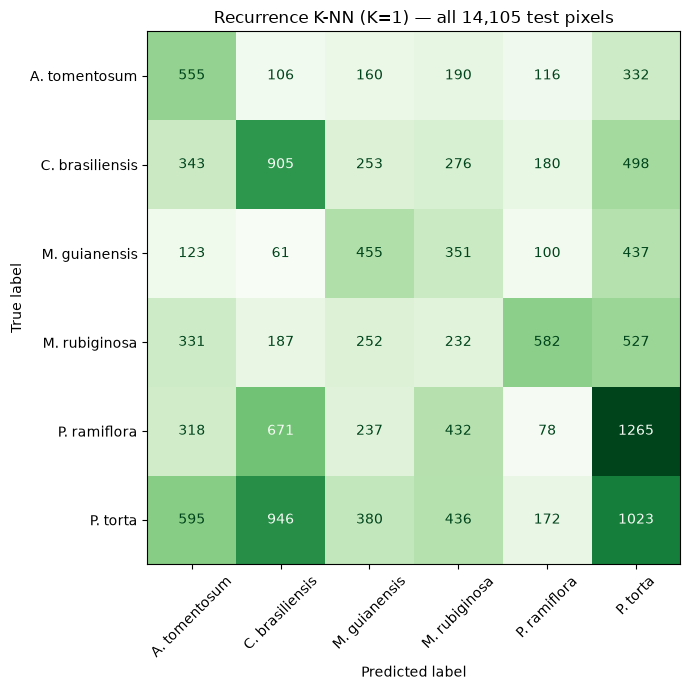

In [28]:
# This shows which species the recurrence model confuses on the test pixels.
# Again, correct predictions are on the diagonal.
cm_rp = confusion_matrix(y_rp_test, y_rp_test_pred, labels=list(SPECIES))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm_rp, display_labels=list(SPECIES.values())).plot(
    ax=ax, cmap="Greens", xticks_rotation=45, colorbar=False)
ax.set_title(f"Recurrence K-NN (K={best_k_rp}) — all {len(y_rp_test):,} test pixels")
plt.tight_layout()
plt.show()

---
## Exercise 5: Compare and Analyze Results

Compare the classification performance between the two approaches using appropriate metrics: **accuracy**, **precision**, **recall**, and **F1-score**.

In [29]:
# Accuracy counts the fraction of correctly classified pixels.
# Macro precision, recall and F1 give each species equal weight, despite unequal counts.
def compute_metrics(y_true, y_pred):
    """Macro averages weight each of the six species equally."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, labels=list(SPECIES), average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, labels=list(SPECIES), average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_true, y_pred, labels=list(SPECIES), average="macro", zero_division=0),
    }

# Both prediction arrays should describe the same test pixels in the same order.
# I check that their label sequences match before comparing the scores.
np.testing.assert_array_equal(y_ts_test, y_rp_test)
metrics_ts = compute_metrics(y_ts_test, y_ts_test_pred)
metrics_rp = compute_metrics(y_rp_test, y_rp_test_pred)
print(f"Matched evaluation: {len(y_ts_test):,} identical test pixels; {len(train_indices):,} fitted training pixels")
print(f"{'Metric':<25} {'Time series':>14} {'Recurrence':>14}")
for name in metrics_ts:
    print(f"{name:<25} {metrics_ts[name]:14.4f} {metrics_rp[name]:14.4f}")
print("Undefined precision/recall is reported as zero; macro metrics include all six species.")

Matched evaluation: 14,105 identical test pixels; 10,996 fitted training pixels
Metric                       Time series     Recurrence
Accuracy                          0.2654         0.2303
Precision (macro)                 0.2089         0.2095
Recall (macro)                    0.3048         0.2452
F1-score (macro)                  0.2298         0.2227
Undefined precision/recall is reported as zero; macro metrics include all six species.


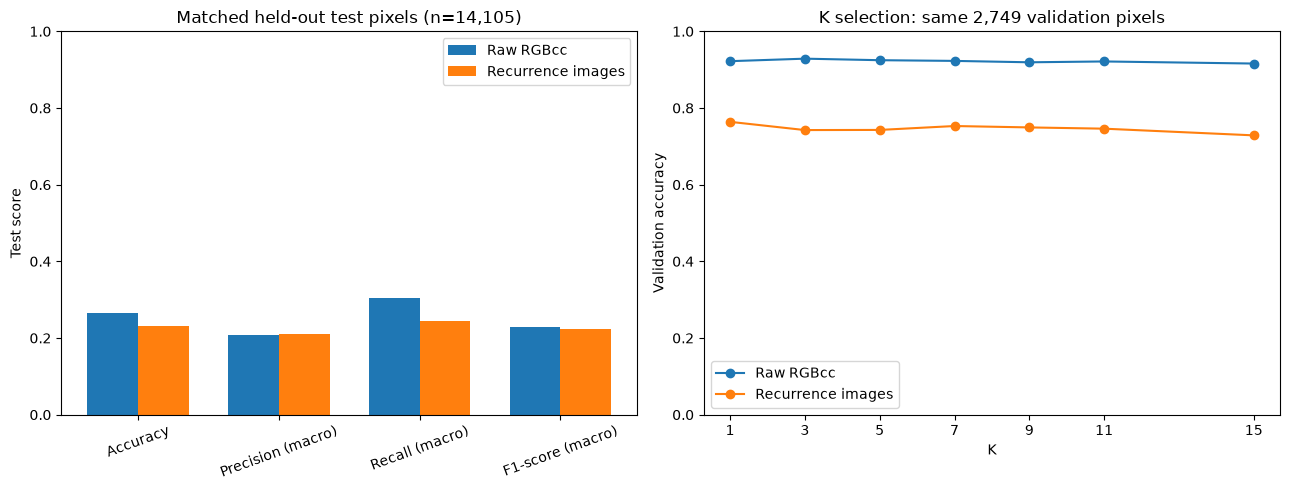

In [30]:
# The left plot compares the final test scores for both representations.
# The right plot shows the validation scores used to choose K, which is a different step.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(metrics_ts))
ax1.bar(x - 0.18, list(metrics_ts.values()), width=0.36, label="Raw RGBcc")
ax1.bar(x + 0.18, list(metrics_rp.values()), width=0.36, label="Recurrence images")
ax1.set(xticks=x, xticklabels=list(metrics_ts), ylim=(0, 1), ylabel="Test score",
        title=f"Matched held-out test pixels (n={len(y_ts_test):,})")
ax1.tick_params(axis="x", rotation=20)
ax1.legend()
ax2.plot(k_values, val_accuracies, "o-", label="Raw RGBcc")
ax2.plot(k_values, val_accuracies_rp, "o-", label="Recurrence images")
ax2.set(xlabel="K", ylabel="Validation accuracy", xticks=k_values, ylim=(0, 1),
        title=f"K selection: same {len(val_indices):,} validation pixels")
ax2.legend()
plt.tight_layout()
# I save this figure as well as displaying it in the notebook.
fig.savefig(RESULTS_DIR / "comparison.png", dpi=150)
plt.show()

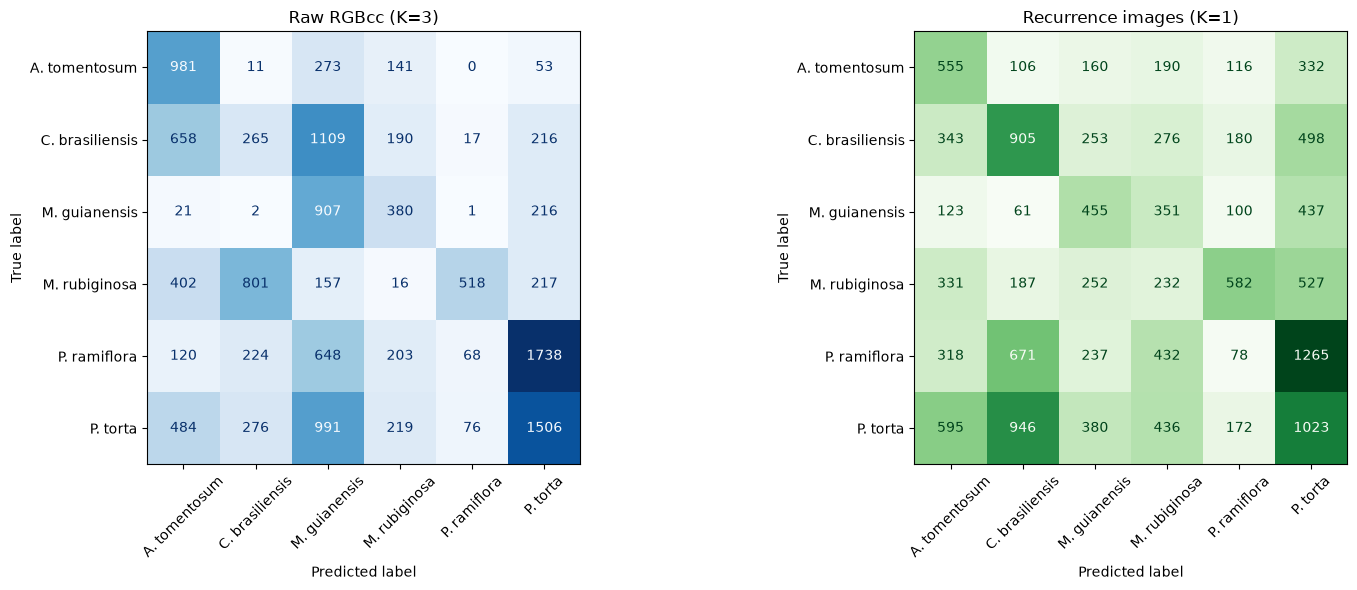

In [31]:
# Putting the confusion matrices together makes the species-level errors easier to compare.
# I compare the counts in the cells; the two plots have separate colour scales.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cm, title, cmap in zip(axes, (cm_ts, cm_rp),
                             (f"Raw RGBcc (K={best_k_ts})", f"Recurrence images (K={best_k_rp})"),
                             ("Blues", "Greens")):
    ConfusionMatrixDisplay(cm, display_labels=list(SPECIES.values())).plot(
        ax=ax, cmap=cmap, xticks_rotation=45, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()

---
## Exercise 6: Critical Reflection

Reflect on the use of image-based representations, such as matrix-structured recurrence plots, for encoding time-series data.

### Discussion Points

Address the following aspects in your analysis:

1. **Strengths of recurrence plot representations**
   - How do recurrence plots capture temporal dynamics that raw time series might not reveal?
   - What patterns (e.g., periodicity, regime changes) become more visible in the RP domain?

2. **Limitations of recurrence plot representations**
   - What information might be lost during the transformation?
   - How sensitive are recurrence plots to noise, time series length, and parameter choices (e.g., ε)?

3. **Data storage implications**
   - Compare the storage requirements of raw time series vs. recurrence plot images.
   - How does upsampling (37 → 140 positions in this dataset) affect storage?

4. **Computational efficiency**
   - What is the computational cost of generating recurrence plots?
   - How does the feature dimensionality of flattened RP images compare to raw time series?

5. **Feature extraction and machine learning**
   - Why might image-based representations benefit from convolutional neural networks (CNNs)?
   - How does K-NN performance compare across the two representations and why?

In [32]:
# I compare the storage needed for the feature values, including their different data types.
# This leaves out labels, file headers and temporary arrays used during calculation.
raw_bytes = X_ts_trainval.nbytes + X_ts_test.nbytes
rp_bytes = X_rp_trainval.nbytes + X_rp_test.nbytes
print(f"Raw feature arrays: {raw_bytes:,} bytes ({raw_bytes / 2**20:.2f} MiB), float32")
print(f"Recurrence feature arrays: {rp_bytes:,} bytes ({rp_bytes / 2**30:.3f} GiB), uint8")
print(f"Entries/sample: {X_ts_trainval.shape[1]} versus {X_rp_trainval.shape[1]}")
print(f"Feature-entry ratio: {58800 / 111:.2f}; byte ratio at these dtypes: {rp_bytes / raw_bytes:.2f}")
# These timings describe this run on this computer, including the different thread settings.
print(f"Raw K-NN: validation {raw_validation_seconds:.2f} s; test {raw_test_seconds:.2f} s")
print(f"RP K-NN: validation {rp_validation_seconds:.2f} s; test {rp_test_seconds:.2f} s")

# I collect the settings, scores and timings so the reported experiment can be checked later.
from datetime import date

results = {
    "schema_version": 1, "run_date": date.today().isoformat(), "seed": RANDOM_STATE,
    "observations": N_TIMESTEPS, "interpolated_positions": 140,
    "samples": {"train": len(train_indices), "validation": len(val_indices), "test": len(y_ts_test)},
    "protocol": "Same full pixel sets; exact Euclidean, uniform votes; validation-only K selection; train-only final fit",
    "distance_tie": "smallest original feature-row index", "vote_tie": "smallest class ID",
    "k_candidates": k_values, "raw_best_k": best_k_ts, "rp_best_k": best_k_rp,
    "raw_validation_accuracy": val_accuracies, "rp_validation_accuracy": val_accuracies_rp,
    "raw_test_metrics": metrics_ts, "rp_test_metrics": metrics_rp,
    "raw_confusion_matrix": cm_ts.tolist(), "rp_confusion_matrix": cm_rp.tolist(),
    "feature_bytes": {"raw_float32": raw_bytes, "rp_uint8": rp_bytes},
    "seconds": {"raw_extraction": raw_generation_seconds, "rp_cache_this_run": rp_cache_seconds,
                "rp_original_generation": rp_trainval_info['generation_seconds'] + rp_test_info['generation_seconds'],
                "raw_validation": raw_validation_seconds, "raw_test": raw_test_seconds,
                "rp_validation": rp_validation_seconds, "rp_test": rp_test_seconds},
    "recurrence_cache": [rp_trainval_info['cache_key'], rp_test_info['cache_key']],
    "limitations": ["Validation pixels share training ROIs", "One held-out ROI per species",
                    "Full assessment rubric not yet reviewed"],
}
(RESULTS_DIR / "experiment_results.json").write_text(json.dumps(results, indent=2) + "\n", encoding="utf-8")
# I also save each prediction, pixel identity and neighbour list to trace how the scores arose.
np.savez_compressed(RESULTS_DIR / "predictions.npz", ids_test=ids_test, y_test=y_ts_test,
                    raw_prediction=y_ts_test_pred, rp_prediction=y_rp_test_pred,
                    val_indices=val_indices, train_indices=train_indices,
                    raw_val_neighbors=ts_val_neighbors, rp_val_neighbors=rp_val_neighbors,
                    raw_test_neighbors=ts_test_neighbors, rp_test_neighbors=rp_test_neighbors)
print("Saved experiment_results.json and predictions.npz alongside the figures and pixel dataset.")

Raw feature arrays: 12,365,400 bytes (11.79 MiB), float32
Recurrence feature arrays: 1,637,580,000 bytes (1.525 GiB), uint8
Entries/sample: 111 versus 58800
Feature-entry ratio: 529.73; byte ratio at these dtypes: 132.43
Raw K-NN: validation 4.57 s; test 20.39 s
RP K-NN: validation 162.61 s; test 758.26 s
Saved experiment_results.json and predictions.npz alongside the figures and pixel dataset.


---
### Reflection — draft for student review

**Observed comparison.** Both models used the same 10,996 training pixels, 2,749
validation pixels and all 14,105 test pixels. Validation selected K=3
for raw RGBcc and K=1 for recurrence images. Their test accuracies were
26.54% and 23.03%; macro F1 scores were
0.2298 and 0.2227. These are measured
results for this fixed dataset and protocol, not a general ranking of the methods.
A constant prediction of the largest training class (P. torta) would achieve
25.18% test accuracy, which is useful context for these scores.
Macro metrics and the confusion matrices matter because the species have unequal
test supports. The lowest raw-series recall was M. rubiginosa (0.76%);
the lowest recurrence recall was P. ramiflora (2.60%).

**Validation versus test.** Selected validation accuracies were 92.87% and
76.39%, substantially above their test accuracies. Validation pixels come from
the same ROIs as training pixels, whereas testing uses different ROIs. Similarity
between neighbouring pixels can make this validation split optimistic. Differences
between regions are a plausible contributor to the gap, but the gap alone does not
establish its cause. We have only one training and one test ROI per species, with
spatially correlated pixels. The many pixel predictions are not independent biological
replicates. A future evaluation could use more ROIs and group-aware validation;
these are future experiments, not changes made after seeing these test results.

**What recurrence images show and lose.** Bright off-diagonal entries represent
large differences between two time positions; dark entries represent similar values.
Blocks or repeated structures can make changes and repeated patterns visible, but
this short series does not by itself establish biological periodicity. Pairwise
differences remove a constant colour offset. Scaling each image/channel by its own
maximum also removes the absolute variation magnitude, and uint8 rounding loses
precision. These changes can discard useful species information as well as emphasize
relative temporal structure. They are possible explanations to investigate, not
isolated causal explanations for the observed score difference. No threshold is
applied, so the template's epsilon discussion is not applicable to this implementation.

**Interpolation and signal quality.** The actual 37 consecutive observations were
linearly interpolated to 140 positions with the same endpoints. This samples the
piecewise-linear curve more densely; it does not add observations or necessarily
place every original knot on the new grid. Noise and low-light artifacts can spread
through pairwise comparisons. For example, the displayed A. tomentosum pixel
(192, 713) has source RGB [6, 0, 0] on DOY 244, which becomes RGBcc [1, 0, 0]. The
sharp colour proportion is present in the supplied dark pixel rather than introduced
by extraction. We retained it and did not tune filtering using the test results.
Chromatic normalization reduces overall brightness effects but can be unstable at
very low intensity; black pixels use the existing explicit zero convention.

**Timing note.** The times below are measurements from the original 11 November 2026
run. A rerun on another computer will produce its own timings in the code outputs.

**Storage and computation.** Raw histories contain 111 float32 values per pixel;
recurrence images contain 58,800 uint8 values. The full selected dataset occupies
12,365,400 bytes (11.79 MiB)
and 1,637,580,000 bytes (1.525 GiB),
respectively: 529.73 times as many entries and
132.43 times the stored bytes
at these dtypes. These numbers exclude metadata, labels, file headers and temporary
working arrays. Original full RP generation took 43.11 s.
Raw K-NN validation/test took 4.57/20.39 s;
RP K-NN took 162.61/758.26 s. These are observed
implementation costs, not a controlled hardware-independent speed ratio: raw used
two BLAS threads; RP used four and the exact symmetry shortcut. Pairwise RP formation
requires quadratic work/storage in the interpolation length. Brute-force K-NN
distance work grows with training samples × query samples × features. Disk caching
avoids repeating generation but does not eliminate this distance cost.

**Image structure and future models.** Flattened K-NN compares pixel values without
learning local image filters. A CNN could learn spatial patterns in recurrence images,
but would require appropriate training data, tuning and a separate fair evaluation;
improvement is not guaranteed. For this comparison, exact symmetry reduction merely
avoids counting identical upper/lower-triangle entries twice and restores the full
Euclidean distance. It changes neither pixel membership nor neighbour rankings.

**Review status.** This draft explains the completed notebook experiment. The student
should review the code, figures and reasoning and revise the discussion in their own
understanding. The full assessment rubric and submission packaging instructions have
not yet been checked; no rubric score or instructor approval is claimed.


---
## Optional extension: Can a different classifier help?

I keep the required K-NN comparison above and ask one extra question: does a
classifier that learns decision boundaries perform better on the same 111 RGBcc
features? This is an exploratory comparison, not a reproduction of a published model.

There is related research behind this exercise. [Faria et al. (2016)](https://doi.org/10.1016/j.patrec.2016.03.005)
combine recurrence representations with image descriptors and classifier fusion.
Their region-based experiment differs from our individual-pixel task.
A [2026 preprint by Gomes et al., including Ricardo](https://arxiv.org/html/2605.00296v1)
uses vision transformers on Itirapina data and reports 61.51% balanced accuracy.
It uses different time-series and evaluation settings; that number is not directly
comparable with our ordinary accuracy. Balanced accuracy corresponds to macro recall
in our tables. Reproducing that transformer would be a larger project.

For a small experiment that runs on a laptop, I compare two scaled RBF support-vector
classifiers (C=1 and C=10) and one random forest. The forest uses 150 trees, a minimum
leaf size of 2 and balanced class weights. These choices are fixed before evaluating
the extra model on the test regions. The [scikit-learn random-forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
describes how multiple decision trees are combined; this is a different approach
from voting among nearby feature vectors.

I use the existing training and validation pixels, fit scaling on training rows
only, and select the candidate with the highest validation accuracy. I then evaluate
only that selected candidate on the same test pixels as before. Validation still
shares the training regions, and the baseline test results were already known when
this extension was designed. It therefore needs confirmation on new regions before
making a broader claim about improvement.


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
import sklearn

# I keep this shortlist fixed instead of adding models after seeing their test scores.
# The pipelines fit their scaling on training pixels only.
extension_models = {
    "Scaled RBF SVC (C=1)": make_pipeline(
        StandardScaler(), SVC(C=1, gamma="scale", class_weight="balanced")
    ),
    "Scaled RBF SVC (C=10)": make_pipeline(
        StandardScaler(), SVC(C=10, gamma="scale", class_weight="balanced")
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, max_features="sqrt",
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
    ),
}
extension_validation = []

# One computation thread keeps this small comparison manageable on a laptop.
with threadpool_limits(limits=1):
    for name, model in extension_models.items():
        fit_started = perf_counter()
        model.fit(X_ts_train, y_ts_train)
        validation_prediction = model.predict(X_ts_val)
        extension_validation.append({
            "name": name,
            "accuracy": float(accuracy_score(y_ts_val, validation_prediction)),
            "macro_f1": float(f1_score(y_ts_val, validation_prediction, average="macro")),
            "fit_and_validation_seconds": perf_counter() - fit_started,
        })

print(f"{'Candidate':<25} {'Validation accuracy':>20} {'Macro F1':>10}")
for row in extension_validation:
    print(f"{row['name']:<25} {row['accuracy']:20.4f} {row['macro_f1']:10.4f}")

# A tie keeps the first candidate in the declared order. Test labels are not used here.
extension_selected = max(extension_validation, key=lambda row: row["accuracy"])["name"]
extension_model = extension_models[extension_selected]
print(f"Selected using validation only: {extension_selected}")


Candidate                  Validation accuracy   Macro F1
Scaled RBF SVC (C=1)                    0.9676     0.9626
Scaled RBF SVC (C=10)                   0.9760     0.9708
Random forest                           0.9942     0.9944
Selected using validation only: Random forest


In [34]:
# I evaluate the selected candidate once, using the original separate test regions.
# Like the K-NN baselines, it has been fitted on training pixels without adding validation.
with threadpool_limits(limits=1):
    extension_test_prediction = extension_model.predict(X_ts_test)
extension_test_metrics = compute_metrics(y_ts_test, extension_test_prediction)
extension_cm = confusion_matrix(y_ts_test, extension_test_prediction, labels=list(SPECIES))

print(f"{'Metric':<25} {'Raw K-NN':>12} {'RP K-NN':>12} {'Extension':>12}")
for metric in metrics_ts:
    print(f"{metric:<25} {metrics_ts[metric]:12.4f} {metrics_rp[metric]:12.4f} "
          f"{extension_test_metrics[metric]:12.4f}")
extension_change_pp = 100 * (extension_test_metrics["Accuracy"] - metrics_ts["Accuracy"])
print(f"Test accuracy change from raw K-NN: {extension_change_pp:+.2f} percentage points")
print("Macro recall is balanced accuracy. A high validation score alone is not a test result.")


Metric                        Raw K-NN      RP K-NN    Extension
Accuracy                        0.2654       0.2303       0.3412
Precision (macro)               0.2089       0.2095       0.2472
Recall (macro)                  0.3048       0.2452       0.3639
F1-score (macro)                0.2298       0.2227       0.2691
Test accuracy change from raw K-NN: +7.59 percentage points
Macro recall is balanced accuracy. A high validation score alone is not a test result.


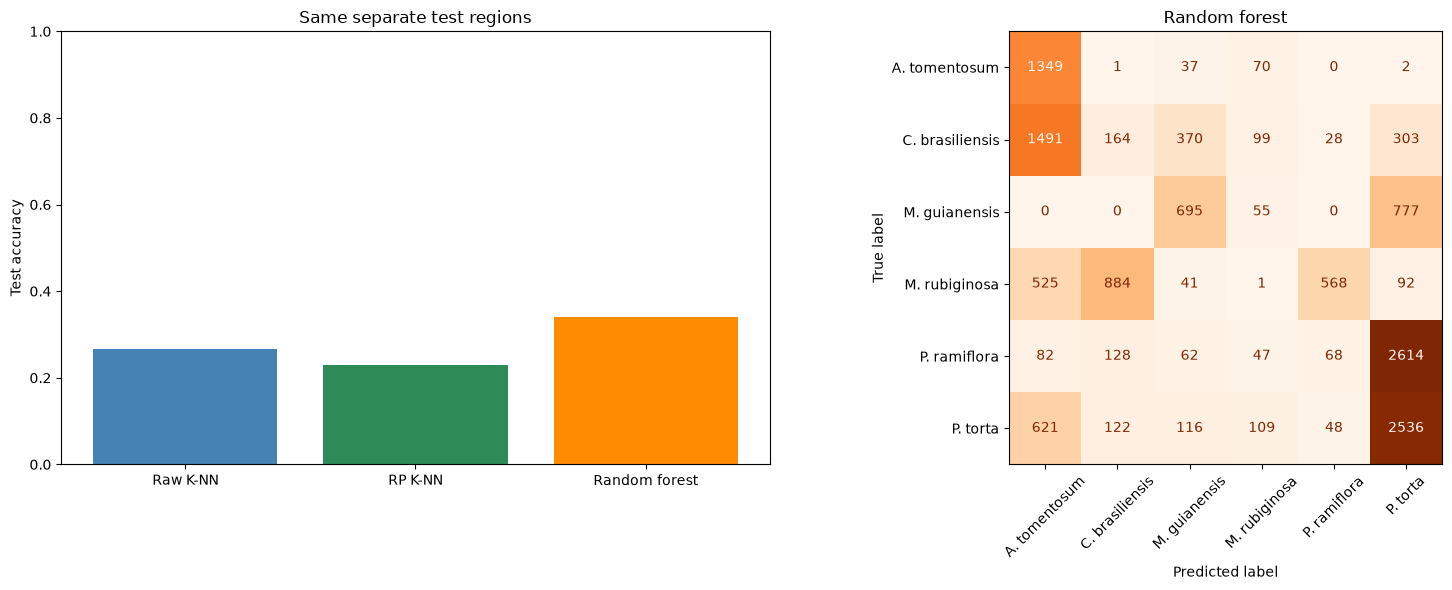

Saved the extension's settings, validation comparison, test predictions and figure.


In [35]:
# I show both the overall accuracy and the species-level mistakes of the extra model.
fig, (score_ax, matrix_ax) = plt.subplots(1, 2, figsize=(16, 6))
score_ax.bar(
    ["Raw K-NN", "RP K-NN", extension_selected],
    [metrics_ts["Accuracy"], metrics_rp["Accuracy"], extension_test_metrics["Accuracy"]],
    color=["steelblue", "seagreen", "darkorange"],
)
score_ax.set(ylabel="Test accuracy", ylim=(0, 1), title="Same separate test regions")
ConfusionMatrixDisplay(extension_cm, display_labels=list(SPECIES.values())).plot(
    ax=matrix_ax, cmap="Oranges", xticks_rotation=45, colorbar=False,
)
matrix_ax.set_title(extension_selected)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "extension_comparison.png", dpi=150)
plt.show()

# These separate files keep the required K-NN results intact.
extension_results = {
    "run_date": date.today().isoformat(), "seed": RANDOM_STATE,
    "feature_representation": "111 RGBcc features; same rows as the raw K-NN baseline",
    "samples": results["samples"], "sklearn_version": sklearn.__version__,
    "candidate_models": {name: str(model) for name, model in extension_models.items()},
    "validation_candidates": extension_validation,
    "selection_rule": "highest validation accuracy; first declared candidate breaks a tie",
    "selected_model": extension_selected, "test_metrics": extension_test_metrics,
    "confusion_matrix": extension_cm.tolist(), "accuracy_change_percentage_points": extension_change_pp,
    "limitations": ["Validation pixels share training ROIs",
                    "Baseline test outcomes were known before designing this exploratory extension",
                    "Confirmation on additional independent regions is needed"],
}
(RESULTS_DIR / "extension_results.json").write_text(
    json.dumps(extension_results, indent=2) + "\n", encoding="utf-8"
)
np.savez_compressed(
    RESULTS_DIR / "extension_predictions.npz", ids_test=ids_test, y_test=y_ts_test,
    prediction=extension_test_prediction, train_indices=train_indices, val_indices=val_indices,
)
print("Saved the extension's settings, validation comparison, test predictions and figure.")


### What this extension can tell me

The relevant comparison is the extra model's score on the separate test regions,
not just its validation score. The table reports any improvement or deterioration
without changing the original K-NN results. A different classifier can use the same
features differently, but it cannot create missing biological variation in the data.

In the 13 November 2026 run, the selected random forest reached **34.12% test
accuracy**, compared with **26.54%** for raw K-NN: a gain of **7.59 percentage points**.
Macro F1 also increased, from **0.2298 to 0.2691**. Its **99.42% validation accuracy**
was still much higher than its test accuracy. So changing the classifier helped on
this split, but it did not solve the difficulty of transferring to separate regions.

A next experiment could compare the original RGB intensities with RGBcc while
keeping the classifier and split fixed. That would test whether brightness carries
useful information lost through chromatic normalization. Spatial neighbourhoods or
learned temporal features are further possibilities, but they need their own controlled
comparison. More independent ROIs would also make validation more informative about
how well a model transfers to a new plant or region.


---
## Optional extension: Trying the other suggested model families

The reflection and first extension above describe earlier stages of the work,
including their review and packaging status. This later experiment takes up
the RGB-intensity and image-model ideas mentioned there. I declared this
additional shortlist before seeing any of its test scores.

The first extension tested a small shortlist. Here I follow up on the suggestions
of SVM, XGBoost, a GLM, a Bayesian network, a vision transformer and transfer
learning. I also compare the original RGB intensities with RGBcc for the tabular
models. This checks whether keeping brightness helps validation, before evaluating
the selected approach on the test regions. It is an exploratory extension: I already knew the earlier baseline test results.

I keep the same 10,996 fitting pixels, 2,749 validation pixels and 14,105 test pixels.
Each family gets a small, declared search. I choose its configuration by validation
accuracy, keeping the first configuration in a tie. Scaling, bin boundaries and
learned parameters use fitting pixels only. I then freeze all seven configurations
before evaluating them on the separate test regions and show every result. The
saved choices are in `results/model_comparison_selection.json`; the full validation
search is in `results/model_comparison_validation.json`.

| Approach | What I try | Input |
| --- | --- | --- |
| SVM | Scaled RBF classifier; C = 0.1, 1 or 10 | 111 RGBcc or original RGB intensity values |
| GLM | Scaled multinomial logistic regression; C = 0.1, 1 or 10 | Same two tabular representations |
| XGBoost | Boosted trees; depth 3 or 6, 150 or 300 trees | Same two tabular representations |
| Gaussian naive Bayes | A simple probability-model reference | Mean, standard deviation and linear trend of each RGBcc channel: nine features |
| Bayesian network | Tree-augmented naive Bayes (TAN); two or three quantile bins, smoothing = 1 | The same nine summaries, discretized using training boundaries |
| CNN transfer learning | Frozen ImageNet MobileNetV3-small, then a scaled logistic classifier | 576 learned features from each recurrence image |
| Vision transformer transfer | Frozen ImageNet ViT-B/32, then a scaled logistic classifier | 768 learned features from each recurrence image |

Multinomial logistic regression is the classification GLM used here
([scikit-learn documentation](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)).
[XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) combines
trees through boosting. The [TAN model](https://ai.stanford.edu/~nir/Abstracts/FrGG1.html)
adds a tree of feature dependencies to naive Bayes. This is a probabilistic graph
classifier, not a Bayesian neural network; its edges are statistical dependencies,
not claims about biological causes.

For the two image models, I use official
[Torchvision pretrained weights](https://docs.pytorch.org/vision/stable/models.html).
Their weights stay fixed; only the final logistic classifier is fitted here, with
C = 0.1, 1 or 10 and balanced class weights. I resize the complete 140 × 140
recurrence image to 224 × 224 and apply ImageNet channel normalization. I do not
crop away time positions or flip the time axes. These features were learned from
natural photographs, so their usefulness for recurrence patterns has to be tested.
This is a compact transfer-learning experiment, not a reproduction of the
spatiotemporal transformer in the [2026 preprint](https://arxiv.org/abs/2605.00296).

The actual training code is in the supplied `experiments/` helpers. The cells below
check and display the saved measured results by default, using the ordinary course
environment. To reproduce all new fits, first install
`requirements-experiments-lock.txt`, select that environment's kernel and set the
switch below to `True`. Run the earlier notebook cells first to build the recurrence
cache. A first full comparison needs internet for the pretrained weights and roughly
an extra hour on the CPU used here; another laptop may take longer.


In [36]:
# I normally display the saved experiment so reviewing the notebook stays practical.
# Switching this on repeats the declared searches and then evaluates their winners.
RUN_EXTENDED_COMPARISON = False

experiment_path = project_path / "experiments"
if str(experiment_path) not in sys.path:
    sys.path.insert(0, str(experiment_path))

if RUN_EXTENDED_COMPARISON:
    from run_comparison import run_comparison
    run_comparison(project_path, refit=True)
else:
    print("Using the saved model comparison; additional training is switched off.")

# This recomputes the scores from the saved predictions and checks the same pixels.
# It also checks that each reported model agrees with the frozen selection record.
from verify_comparison import verify_results as verify_model_comparison
comparison_check = verify_model_comparison(project_path)
print(f"Checked {comparison_check['models_checked']} models on the original test pixels.")


Using the saved model comparison; additional training is switched off.
Checked 10 models on the original test pixels.


In [37]:
# I keep validation and test scores in separate columns: they answer different questions.
model_comparison = json.loads((RESULTS_DIR / "model_comparison.json").read_text(encoding="utf-8"))
print(f"{'Model':<29} {'Validation':>11} {'Test acc.':>11} {'Balanced':>11} {'Macro F1':>10}")
for row in model_comparison["rows"]:
    score = row["test_metrics"]
    print(f"{row['name']:<29} {row['validation_accuracy']:>10.2%} "
          f"{score['Accuracy']:>10.2%} {row['balanced_accuracy']:>10.2%} "
          f"{score['F1-score (macro)']:>10.4f}")
print("Balanced accuracy is macro recall: each of the six species gets equal weight.")
print("All rows use the same separate test regions; some use different input features.")


Model                          Validation   Test acc.    Balanced   Macro F1
Raw K-NN                          92.87%     26.54%     30.48%     0.2298
Recurrence K-NN                   76.39%     23.03%     24.52%     0.2227
Random forest                     99.42%     34.12%     36.39%     0.2691
SVM (RBF)                         99.49%     31.95%     33.36%     0.2570
Multinomial logistic GLM         100.00%     36.39%     38.91%     0.3146
XGBoost                           99.75%     33.92%     35.57%     0.2607
Gaussian naive Bayes              80.54%     24.72%     25.33%     0.2034
Bayesian network (TAN)            88.14%     34.12%     36.78%     0.2850
CNN transfer (MobileNet)          80.28%     23.05%     25.49%     0.2196
ViT transfer (B/32)               82.94%     25.27%     28.01%     0.2379
Balanced accuracy is macro recall: each of the six species gets equal weight.
All rows use the same separate test regions; some use different input features.


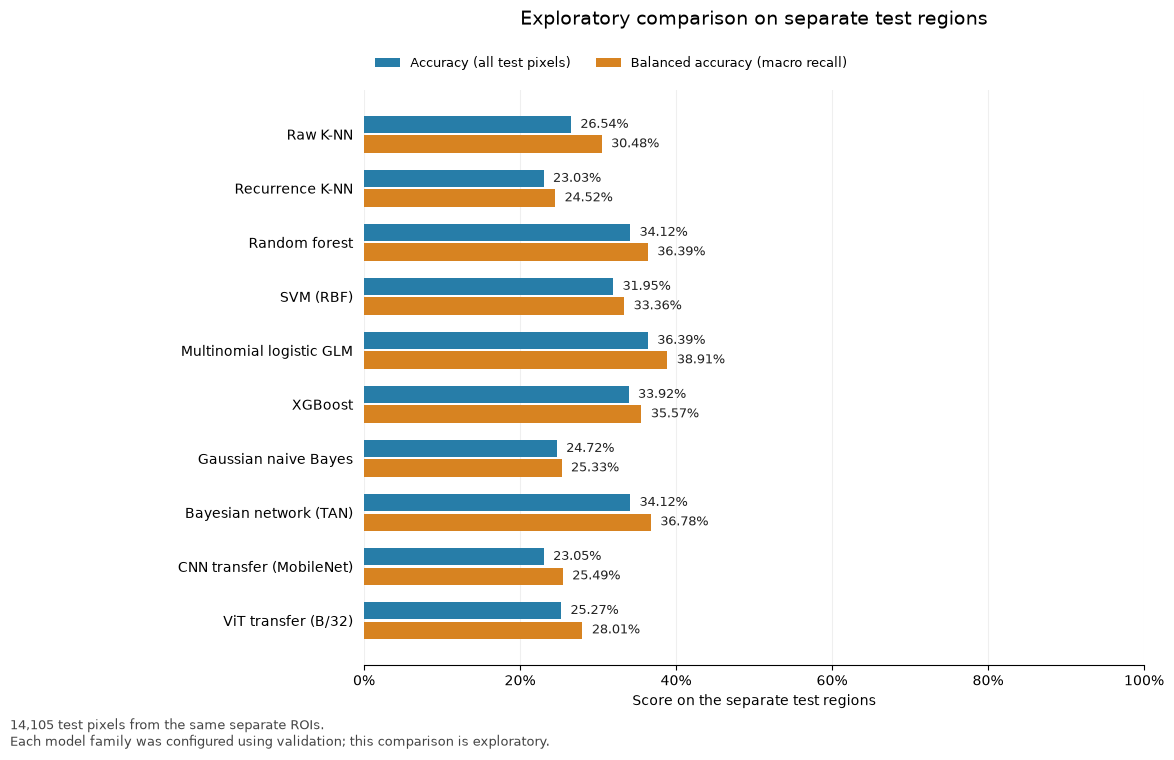

In [38]:
# This makes it easier to see whether the overall and per-species scores tell the same story.
from plot_comparison import plot_comparison
comparison_figure = plot_comparison(project_path, save=False)
plt.show()


### How I interpret this comparison — draft for student review

In the 13 November 2026 run, **multinomial logistic regression on the original
RGB intensities** had the highest observed test accuracy: **36.39%**, compared with
**34.12%** for the earlier random forest and **26.54%** for raw RGBcc K-NN. That is
a gain of **2.27 percentage points** over the forest. Balanced accuracy also rose
from **36.39% to 38.91%**, and macro F1 from **0.2691 to 0.3146**. So there is an
improvement on this split, but it is modest. The SVM reached 31.95%, XGBoost 33.92%,
Gaussian naive Bayes 24.72%, and TAN 34.12% ordinary test accuracy. The frozen CNN
and transformer reached 23.05% and 25.27%, respectively; these particular transfer
approaches did not improve the forest baseline. Their results do not establish
that all CNNs or transformers are unsuitable for phenology.

Within the recurrence-image approaches, the transformer did improve on
recurrence K-NN (25.27% versus 23.03%, a gain of 2.24 percentage points), though
it remained below the raw RGBcc K-NN score of 26.54%.

The logistic model had **100% validation accuracy** but only **36.39% test accuracy**.
That difference is a useful reminder that recognizing pixels within familiar
regions is much easier here than transferring to a separate region. Both the model
and its input representation differ from the random forest, so I cannot attribute
the gain to logistic regression or retained brightness separately.

The gain is uneven across species. C. brasiliensis recall rises from 6.68%
with the forest to 40.61% with the GLM, but recall falls for A. tomentosum and
P. torta. The GLM still correctly recognizes none of the M. rubiginosa test
pixels and only 2.33% of P. ramiflora pixels. A higher overall score therefore
does not mean that the difficult species have been resolved.

The test table is the result of the fixed experiment above. Validation still uses
pixels from the training ROIs, so even a validation score near 100% does not show
that the model will recognize a new region. Training and validation can share
region-specific appearance, and nearby pixels are correlated.

This table compares complete approaches. For example, the Bayesian models use
summary statistics and the image models use pretrained features. Their differences
cannot be attributed to the classifier alone. The best observed test row is a
descriptive finding from this split, not a fresh independent confirmation after
choosing that row. I would need additional held-out regions to establish whether
it is reliably better. I did not use these scores to start another tuning round.

The paper's 61.51% is **balanced accuracy**, which is the `Balanced` column here.
It uses a different model and evaluation protocol, so crossing that number would
not by itself reproduce or outperform the paper. I also cannot treat thousands of
correlated pixels as thousands of independent plants when assessing certainty.


So 